<center><h1>Last_First_HW6</h1></center>

Name: yiyi zheng
<br>
Github Username: yiyizheng111
<br>
USC ID: 7092417109

## 1. Tree-Based Methods

Import packages

In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


### (a) Download the APS Failure data

In [2]:

# Check the data folder

DATA_DIR = Path("Homework 6 Data")

print("Data folder exists:", DATA_DIR.exists())

print("\nFiles in the data folder:")

for file_path in sorted(DATA_DIR.rglob("*")):
    if file_path.is_file() and not file_path.name.startswith("."):
        print(file_path.relative_to(DATA_DIR))


Data folder exists: True

Files in the data folder:
aps_failure_description.txt
aps_failure_test_set.csv
aps_failure_training_set.csv


In [3]:

# Question 1(a): Load the APS Failure dataset

aps_train = pd.read_csv(
    DATA_DIR / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

aps_test = pd.read_csv(
    DATA_DIR / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training set shape:", aps_train.shape)
print("Test set shape:", aps_test.shape)

print("\nFirst five columns:")
print(aps_train.columns[:5].tolist())

print("\nTraining class distribution:")
print(aps_train["class"].value_counts())

print("\nTest class distribution:")
print(aps_test["class"].value_counts())


Training set shape: (60000, 171)
Test set shape: (16000, 171)

First five columns:
['class', 'aa_000', 'ab_000', 'ac_000', 'ad_000']

Training class distribution:
neg    59000
pos     1000
Name: class, dtype: int64

Test class distribution:
neg    15625
pos      375
Name: class, dtype: int64


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [4]:

# Question 1(b)(i): Check missing values

X_train = aps_train.drop(columns=["class"])
X_test = aps_test.drop(columns=["class"])

train_missing = X_train.isna().sum()
test_missing = X_test.isna().sum()

print("Training missing values:", train_missing.sum())
print("Test missing values:", test_missing.sum())

print("\nTraining missing percentage:",
      round(X_train.isna().mean().mean() * 100, 2), "%")

print("Test missing percentage:",
      round(X_test.isna().mean().mean() * 100, 2), "%")

print("\nFeatures with missing values in training:",
      (train_missing > 0).sum())

print("\nTop 10 features with most missing values:")
print(train_missing.sort_values(ascending=False).head(10))


Training missing values: 850015
Test missing values: 228680

Training missing percentage: 8.33 %
Test missing percentage: 8.41 %

Features with missing values in training: 169

Top 10 features with most missing values:
br_000    49264
bq_000    48722
bp_000    47740
bo_000    46333
cr_000    46329
ab_000    46329
bn_000    44009
bm_000    39549
bl_000    27277
bk_000    23034
dtype: int64


In [5]:

# Question 1(b)(i): Median imputation

from sklearn.impute import SimpleImputer

# Fit the imputer using training data
imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply the same imputer to test data
X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training shape:", X_train_imp.shape)
print("Test shape:", X_test_imp.shape)

print("\nMissing values after imputation:")
print("Training:", X_train_imp.isna().sum().sum())
print("Test:", X_test_imp.isna().sum().sum())


Training shape: (60000, 170)
Test shape: (16000, 170)

Missing values after imputation:
Training: 0
Test: 0


There are 850,015 missing values in the training set and 228,680 missing values in the test set. 8.33% of the training data is missing.

Common methods for handling missing values include mean imputation, median imputation, and KNN imputation.

I chose median imputation because it is less affected by extreme values.

After imputation, there were no missing values left in either dataset.

#### (ii) Calculate the coefficient of variation

In [6]:

# Question 1(b)(ii): Coefficient of Variation

# Calculate sample standard deviation and mean
feature_std = X_train_imp.std(ddof=1)
feature_mean = X_train_imp.mean()

# Calculate CV for each feature
cv_values = feature_std / feature_mean.replace(0, np.nan)

# Sort CV values from highest to lowest
cv_sorted = cv_values.sort_values(ascending=False)

print("Number of features:", len(cv_values))
print("Features with undefined CV:", cv_values.isna().sum())

print("\nTop 15 features with highest CV:")
print(cv_sorted.head(15).round(4))


Number of features: 170
Features with undefined CV: 0

Top 15 features with highest CV:
cf_000    244.8875
co_000    244.5074
ad_000    244.3228
cs_009    237.9306
dh_000    123.2161
dj_000    117.4942
ag_000     92.9178
as_000     87.3325
ay_009     84.7337
ak_000     80.4250
az_009     77.8385
ch_000     77.4539
au_000     68.8828
cr_000     58.0781
ay_001     52.8247
dtype: float64


I calculated the coefficient of variation (CV) for all 170 features using the training set.

All 170 features had valid CV values. The features with the highest CV were cf_000, co_000, ad_000, and cs_009.

Some CV values were very large. This may happen when a feature has a small mean compared to its standard deviation.

A high CV means the feature has high relative variation, but it does not necessarily mean the feature is important for predicting the class.

#### (iii) Plot a correlation matrix

Correlation matrix shape: (170, 170)


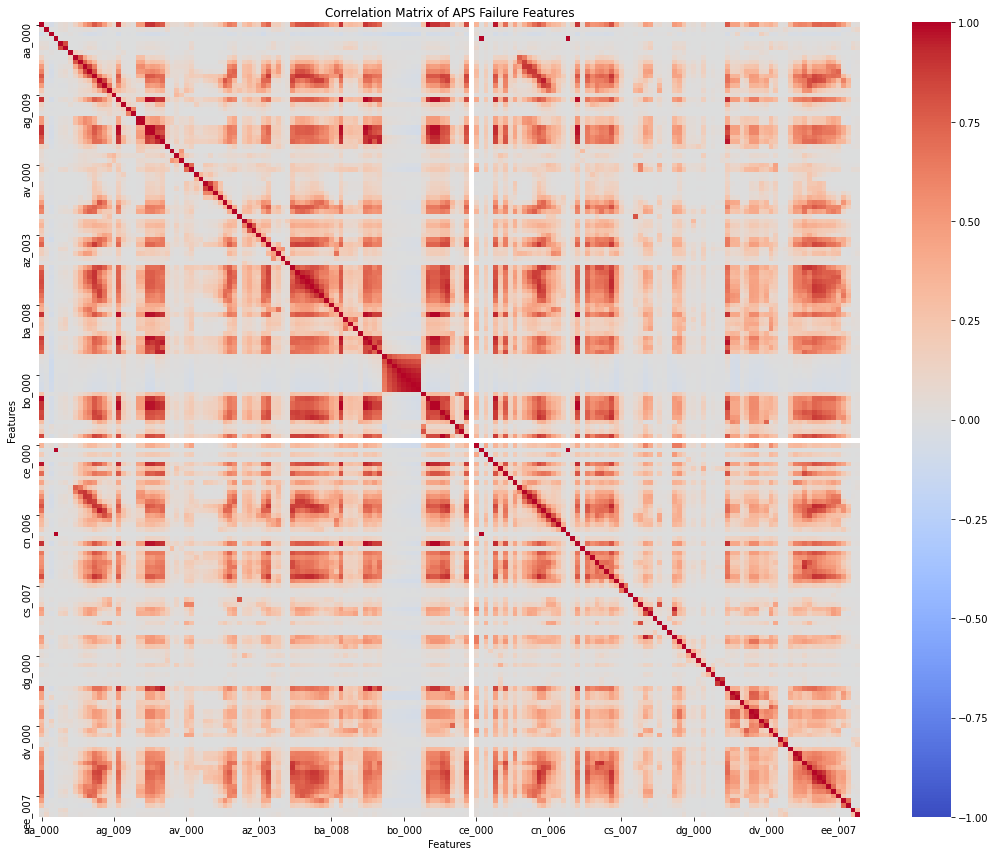

In [7]:

# Question 1(b)(iii): Correlation Matrix

import seaborn as sns

# Calculate correlation matrix
corr_matrix = X_train_imp.corr()

print("Correlation matrix shape:", corr_matrix.shape)

# Plot the correlation matrix
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=15,
    yticklabels=15
)

plt.title("Correlation Matrix of APS Failure Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


I plotted the correlation matrix for all 170 features using the training set.

Some features have strong positive correlations, as shown by the red areas in the heatmap. This means these features may contain similar information.

Many other features have relatively weak correlations. However, the correlation matrix alone cannot tell us which features are important for predicting APS failure.

#### (iv) Make scatter plots and box plots

Top 13 features:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


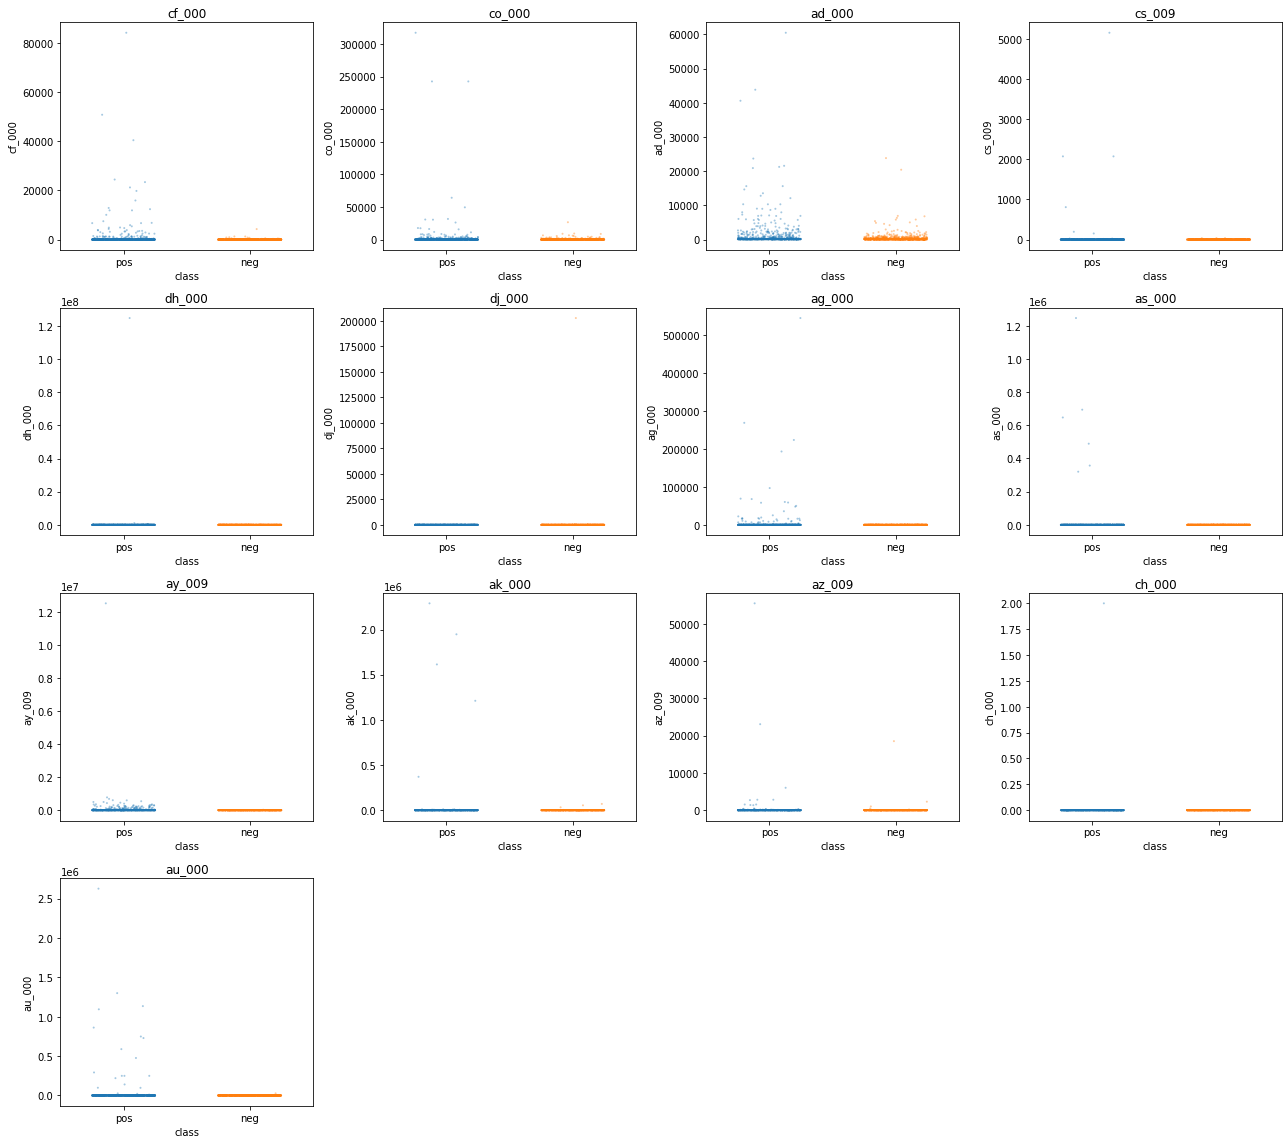

In [8]:

# Question 1(b)(iv): Scatter plots for top 13 CV features

top_13_features = cv_sorted.head(13).index.tolist()

print("Top 13 features:")
print(top_13_features)

# Sample data from both classes for visualization
pos_rows = aps_train[aps_train["class"] == "pos"].index
neg_rows = aps_train[aps_train["class"] == "neg"].sample(
    n=1000, random_state=42
).index

plot_rows = pos_rows.append(neg_rows)

plot_df = X_train_imp.loc[plot_rows, top_13_features].copy()
plot_df["class"] = aps_train.loc[plot_rows, "class"]

# Create scatter plots
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(top_13_features):
    sns.stripplot(
        data=plot_df,
        x="class",
        y=feature,
        jitter=0.25,
        size=2,
        alpha=0.4,
        ax=axes[i]
    )
    axes[i].set_title(feature)

for i in range(13, 16):
    axes[i].axis("off")

plt.tight_layout()
plt.show()


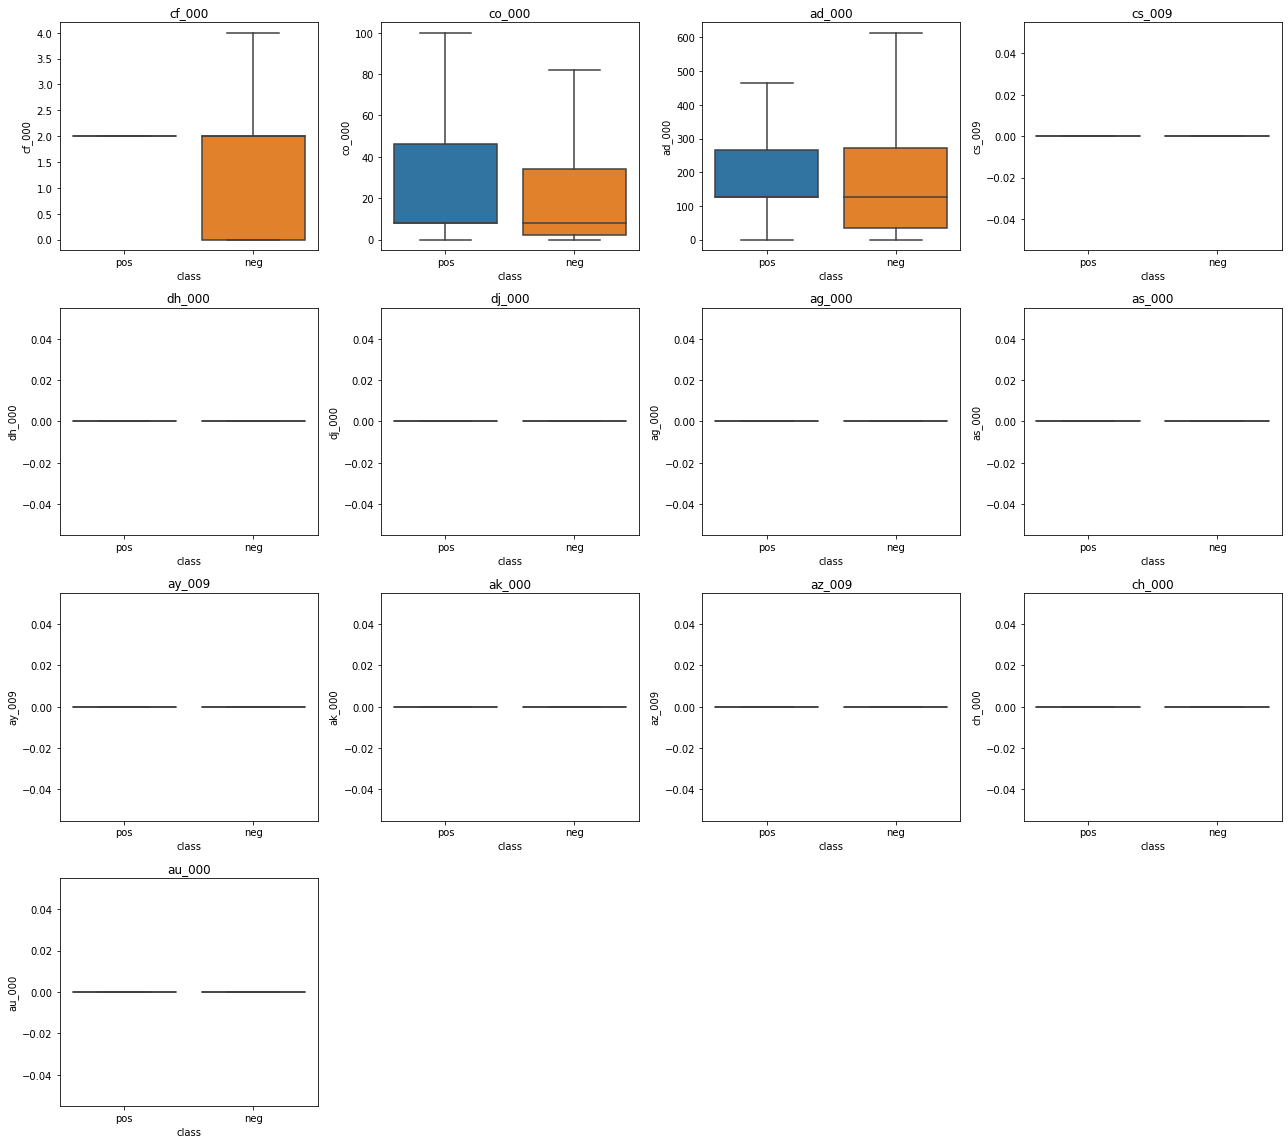

In [9]:

# Question 1(b)(iv): Box plots for top 13 CV features

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(top_13_features):
    sns.boxplot(
        data=plot_df,
        x="class",
        y=feature,
        showfliers=False,
        ax=axes[i]
    )
    axes[i].set_title(feature)

# Hide the unused plots
for i in range(13, 16):
    axes[i].axis("off")

plt.tight_layout()
plt.show()


I selected the 13 features with the highest CV values and plotted scatter plots and box plots for them.

From the scatter plots, most values were close to zero, but some features had very large outliers, especially in the positive class.

In the box plots, many features appeared as flat lines because most of their values were concentrated near zero. Some features, such as cf_000 and co_000, showed differences between the two classes.

However, the two classes still had overlapping distributions. Therefore, we cannot determine the statistical significance of these features from the plots alone. We would need further analysis to understand their importance.

#### (v) Is this data set imbalanced?

In [10]:

# Question 1(b)(v): Check class imbalance

train_counts = aps_train["class"].value_counts()
test_counts = aps_test["class"].value_counts()

print("Training set:")
print(train_counts)

print("\nTraining class percentages:")
print((train_counts / len(aps_train) * 100).round(2))

print("\nTest set:")
print(test_counts)

print("\nTest class percentages:")
print((test_counts / len(aps_test) * 100).round(2))

print("\nTraining negative-to-positive ratio:",
      train_counts["neg"] / train_counts["pos"])


Training set:
neg    59000
pos     1000
Name: class, dtype: int64

Training class percentages:
neg    98.33
pos     1.67
Name: class, dtype: float64

Test set:
neg    15625
pos      375
Name: class, dtype: int64

Test class percentages:
neg    97.66
pos     2.34
Name: class, dtype: float64

Training negative-to-positive ratio: 59.0


The training set contains 59,000 negative observations and 1,000 positive observations. The positive class only makes up 1.67% of the training data.

The ratio of negative to positive observations is 59:1, so the dataset is highly imbalanced.

The test set is also imbalanced, with 15,625 negative and 375 positive observations.

Because of this imbalance, accuracy alone may not be enough to evaluate the classification models.

### (c) Train a random forest

In [11]:

# Question 1(c): Random Forest without class imbalance compensation

from sklearn.ensemble import RandomForestClassifier

# Convert class labels into 0 and 1
y_train = (aps_train["class"] == "pos").astype(int)
y_test = (aps_test["class"] == "pos").astype(int)

# Build the random forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_imp, y_train)

# Calculate OOB error
rf_oob_error = 1 - rf_model.oob_score_

print("Random Forest training completed.")
print("Number of trees:", rf_model.n_estimators)
print("OOB Error:", rf_oob_error)


Random Forest training completed.
Number of trees: 100
OOB Error: 0.006166666666666654


In [12]:

# Question 1(c): Confusion Matrix and Misclassification Error

from sklearn.metrics import confusion_matrix

# Make predictions
rf_train_pred = rf_model.predict(X_train_imp)
rf_test_pred = rf_model.predict(X_test_imp)

# Calculate confusion matrices
rf_train_cm = confusion_matrix(y_train, rf_train_pred)
rf_test_cm = confusion_matrix(y_test, rf_test_pred)

print("Training Confusion Matrix:")
print(pd.DataFrame(
    rf_train_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

print("\nTest Confusion Matrix:")
print(pd.DataFrame(
    rf_test_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

# Calculate misclassification errors
rf_train_error = np.mean(y_train != rf_train_pred)
rf_test_error = np.mean(y_test != rf_test_pred)

print("\nTraining Misclassification Error:", rf_train_error)
print("Test Misclassification Error:", rf_test_error)
print("OOB Error:", rf_oob_error)


Training Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               59000                   0
Actual Positive                   1                 999

Test Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               15610                  15
Actual Positive                 106                 269

Training Misclassification Error: 1.6666666666666667e-05
Test Misclassification Error: 0.0075625
OOB Error: 0.006166666666666654


Training AUC: 1.0
Test AUC: 0.992745


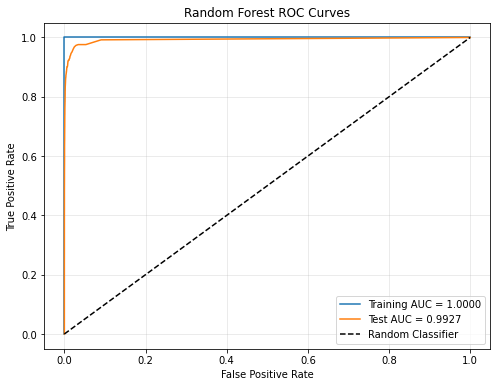

In [13]:

# Question 1(c): ROC Curves and AUC

from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for the positive class
rf_train_prob = rf_model.predict_proba(X_train_imp)[:, 1]
rf_test_prob = rf_model.predict_proba(X_test_imp)[:, 1]

# Calculate AUC
rf_train_auc = roc_auc_score(y_train, rf_train_prob)
rf_test_auc = roc_auc_score(y_test, rf_test_prob)

print("Training AUC:", round(rf_train_auc, 6))
print("Test AUC:", round(rf_test_auc, 6))

# Calculate ROC curves
fpr_train, tpr_train, _ = roc_curve(y_train, rf_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test, rf_test_prob)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(fpr_train, tpr_train,
         label=f"Training AUC = {rf_train_auc:.4f}")

plt.plot(fpr_test, tpr_test,
         label=f"Test AUC = {rf_test_auc:.4f}")

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


I trained a Random Forest with 100 trees without adjusting for class imbalance.

The training misclassification error was 0.000017, and the test misclassification error was 0.007563. The OOB error was 0.006167, which was close to the test error.

The training AUC was 1.0000, and the test AUC was 0.9927. The ROC curves show that the model can distinguish the two classes very well.

However, the test confusion matrix shows that 106 positive observations were incorrectly classified as negative. This means the model still missed about 28.27% of the positive cases.

Overall, the Random Forest performed well, but the class imbalance may affect its ability to identify positive cases.

### (d) Research class imbalance in random forest

In [14]:

# Question 1(d): Random Forest with class imbalance compensation

rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

# Train the balanced random forest
rf_balanced.fit(X_train_imp, y_train)

# Calculate OOB error
rf_balanced_oob_error = 1 - rf_balanced.oob_score_

print("Balanced Random Forest training completed.")
print("Number of trees:", rf_balanced.n_estimators)
print("Class weight:", rf_balanced.class_weight)
print("OOB Error:", rf_balanced_oob_error)


Balanced Random Forest training completed.
Number of trees: 100
Class weight: balanced
OOB Error: 0.008199999999999985


In [15]:

# Question 1(d): Confusion Matrix and Misclassification Error

# Make predictions
rf_balanced_train_pred = rf_balanced.predict(X_train_imp)
rf_balanced_test_pred = rf_balanced.predict(X_test_imp)

# Calculate confusion matrices
rf_balanced_train_cm = confusion_matrix(
    y_train, rf_balanced_train_pred
)

rf_balanced_test_cm = confusion_matrix(
    y_test, rf_balanced_test_pred
)

print("Balanced Random Forest - Training Confusion Matrix:")
print(pd.DataFrame(
    rf_balanced_train_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

print("\nBalanced Random Forest - Test Confusion Matrix:")
print(pd.DataFrame(
    rf_balanced_test_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

# Calculate errors
rf_balanced_train_error = np.mean(
    y_train != rf_balanced_train_pred
)

rf_balanced_test_error = np.mean(
    y_test != rf_balanced_test_pred
)

print("\nTraining Misclassification Error:", rf_balanced_train_error)
print("Test Misclassification Error:", rf_balanced_test_error)
print("OOB Error:", rf_balanced_oob_error)

# Calculate positive class recall
rf_balanced_recall = (
    rf_balanced_test_cm[1, 1] / rf_balanced_test_cm[1].sum()
)

print("Test Positive Recall:", rf_balanced_recall)


Balanced Random Forest - Training Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               59000                   0
Actual Positive                   1                 999

Balanced Random Forest - Test Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               15611                  14
Actual Positive                 160                 215

Training Misclassification Error: 1.6666666666666667e-05
Test Misclassification Error: 0.010875
OOB Error: 0.008199999999999985
Test Positive Recall: 0.5733333333333334


Training AUC: 1.0
Test AUC: 0.991944


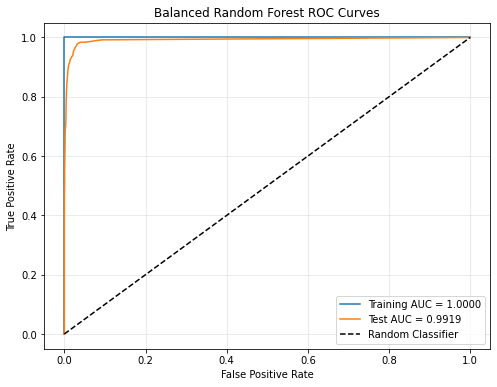

In [16]:

# Question 1(d): ROC Curves and AUC for Balanced Random Forest

# Get predicted probabilities
rf_balanced_train_prob = rf_balanced.predict_proba(X_train_imp)[:, 1]
rf_balanced_test_prob = rf_balanced.predict_proba(X_test_imp)[:, 1]

# Calculate AUC
rf_balanced_train_auc = roc_auc_score(
    y_train, rf_balanced_train_prob
)

rf_balanced_test_auc = roc_auc_score(
    y_test, rf_balanced_test_prob
)

print("Training AUC:", round(rf_balanced_train_auc, 6))
print("Test AUC:", round(rf_balanced_test_auc, 6))

# Calculate ROC curves
fpr_train_bal, tpr_train_bal, _ = roc_curve(
    y_train, rf_balanced_train_prob
)

fpr_test_bal, tpr_test_bal, _ = roc_curve(
    y_test, rf_balanced_test_prob
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train_bal, tpr_train_bal,
    label=f"Training AUC = {rf_balanced_train_auc:.4f}"
)

plt.plot(
    fpr_test_bal, tpr_test_bal,
    label=f"Test AUC = {rf_balanced_test_auc:.4f}"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Class imbalance in Random Forest can be handled using class weighting, undersampling, oversampling, or balanced bootstrap sampling. In this experiment, I used class weighting to give more importance to the minority class.

I trained another Random Forest using class_weight="balanced" to handle the class imbalance.

The training misclassification error was 0.000017, and the test error was 0.010875. The OOB error was 0.008200.

The training AUC was 1.0000, and the test AUC was 0.991944.

Compared with the original Random Forest, the balanced model had a higher test error and slightly lower test AUC.

The number of false negatives increased from 106 to 160, and the positive recall decreased from 71.73% to 57.33%.

In this case, using class weights did not improve the model's performance. The original Random Forest performed better on the test set.

### (e) XGBoost and Model Trees

In [20]:

# Question 1(e): XGBoost with L1 regularization

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build the XGBoost model
xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=120,
    max_depth=4,
    learning_rate=0.1,
    tree_method="hist",
    random_state=42,
    n_jobs=2,
    eval_metric="logloss"
)

# Imputation is done separately within each CV fold
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", xgb_model)
])

# L1 regularization values
alpha_values = [0, 0.001, 0.01, 0.1, 1]

# Use stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_search = GridSearchCV(
    xgb_pipeline,
    param_grid={"xgb__reg_alpha": alpha_values},
    cv=cv,
    scoring={
        "auc": "roc_auc",
        "accuracy": "accuracy"
    },
    refit="auc",
    n_jobs=1
)

# Train using the original training features
xgb_search.fit(X_train, y_train)

# Display CV results
xgb_cv_results = pd.DataFrame({
    "Alpha": alpha_values,
    "CV AUC": xgb_search.cv_results_["mean_test_auc"],
    "CV Error": 1 - xgb_search.cv_results_["mean_test_accuracy"]
})

print("XGBoost Cross-Validation Results:")
print(xgb_cv_results.round(6).to_string(index=False))

print("\nBest alpha:", xgb_search.best_params_["xgb__reg_alpha"])
print("Best CV AUC:", xgb_search.best_score_)
print(
    "CV Error of selected model:",
    1 - xgb_search.cv_results_["mean_test_accuracy"][xgb_search.best_index_]
)


XGBoost Cross-Validation Results:
 Alpha   CV AUC  CV Error
 0.000 0.989097  0.005900
 0.001 0.989144  0.005950
 0.010 0.988725  0.006050
 0.100 0.989868  0.005933
 1.000 0.989561  0.005933

Best alpha: 0.1
Best CV AUC: 0.9898683898305085
CV Error of selected model: 0.005933333333333346


In [21]:

# Question 1(e): XGBoost Confusion Matrix and Test Error

# Get the best XGBoost model
xgb_final = xgb_search.best_estimator_

# Make predictions using the original features
xgb_train_pred = xgb_final.predict(X_train)
xgb_test_pred = xgb_final.predict(X_test)

# Calculate confusion matrices
xgb_train_cm = confusion_matrix(y_train, xgb_train_pred)
xgb_test_cm = confusion_matrix(y_test, xgb_test_pred)

print("XGBoost Training Confusion Matrix:")
print(pd.DataFrame(
    xgb_train_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

print("\nXGBoost Test Confusion Matrix:")
print(pd.DataFrame(
    xgb_test_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

# Calculate misclassification errors
xgb_train_error = np.mean(y_train != xgb_train_pred)
xgb_test_error = np.mean(y_test != xgb_test_pred)

print("\nTraining Misclassification Error:", xgb_train_error)
print("Test Misclassification Error:", xgb_test_error)

print("Cross-Validation Error:",
      1 - xgb_search.cv_results_["mean_test_accuracy"][xgb_search.best_index_])

# Calculate positive recall
xgb_test_recall = xgb_test_cm[1, 1] / xgb_test_cm[1].sum()

print("Test Positive Recall:", xgb_test_recall)


XGBoost Training Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               58982                  18
Actual Positive                 130                 870

XGBoost Test Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               15608                  17
Actual Positive                  87                 288

Training Misclassification Error: 0.0024666666666666665
Test Misclassification Error: 0.0065
Cross-Validation Error: 0.005933333333333346
Test Positive Recall: 0.768


Training AUC: 0.99872
Test AUC: 0.996395


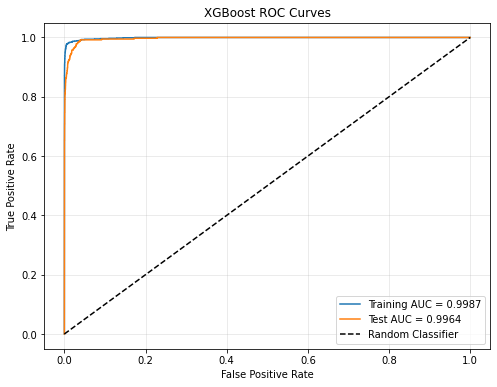

In [22]:

# Question 1(e): XGBoost ROC Curves and AUC

# Get predicted probabilities for the positive class
xgb_train_prob = xgb_final.predict_proba(X_train)[:, 1]
xgb_test_prob = xgb_final.predict_proba(X_test)[:, 1]

# Calculate AUC
xgb_train_auc = roc_auc_score(y_train, xgb_train_prob)
xgb_test_auc = roc_auc_score(y_test, xgb_test_prob)

print("Training AUC:", round(xgb_train_auc, 6))
print("Test AUC:", round(xgb_test_auc, 6))

# Calculate ROC curves
fpr_train_xgb, tpr_train_xgb, _ = roc_curve(
    y_train, xgb_train_prob
)

fpr_test_xgb, tpr_test_xgb, _ = roc_curve(
    y_test, xgb_test_prob
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train_xgb, tpr_train_xgb,
    label=f"Training AUC = {xgb_train_auc:.4f}"
)

plt.plot(
    fpr_test_xgb, tpr_test_xgb,
    label=f"Test AUC = {xgb_test_auc:.4f}"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


I trained an XGBoost classifier without adjusting for class imbalance. I used 5-fold cross-validation to choose the L1 regularization parameter.

The best alpha was 0.1. The cross-validation AUC was 0.989868, and the CV error was 0.005933.

The training misclassification error was 0.002467, and the test error was 0.006500. The CV error was close to the test error.

The training AUC was 0.998720, and the test AUC was 0.996395.

Compared with the two Random Forest models, XGBoost had the lowest test error and the highest test AUC. It also correctly identified 288 out of 375 positive cases, giving a positive recall of 76.80%.

Overall, XGBoost performed better in this experiment, although it still missed 87 positive observations.

### (f) Use SMOTE to pre-process your data

In [26]:

# Question 1(f): SMOTE + XGBoost with L1 regularization

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Build the XGBoost classifier
smote_xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=120,
    max_depth=4,
    learning_rate=0.1,
    tree_method="hist",
    random_state=42,
    n_jobs=2,
    eval_metric="logloss"
)

# Apply SMOTE only to the training data in each CV fold
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=42)),
    ("xgb", smote_xgb_model)
])

# Use the same alpha values as Question 1(e)
alpha_values = [0, 0.001, 0.01, 0.1, 1]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Select alpha using cross-validation
smote_search = GridSearchCV(
    smote_pipeline,
    param_grid={"xgb__reg_alpha": alpha_values},
    cv=cv,
    scoring={
        "auc": "roc_auc",
        "accuracy": "accuracy"
    },
    refit="auc",
    n_jobs=1
)

# Train using the original training data
smote_search.fit(X_train, y_train)

# Show cross-validation results
smote_cv_results = pd.DataFrame({
    "Alpha": alpha_values,
    "CV AUC": smote_search.cv_results_["mean_test_auc"],
    "CV Error": 1 - smote_search.cv_results_["mean_test_accuracy"]
})

print("SMOTE + XGBoost Cross-Validation Results:")
print(smote_cv_results.round(6).to_string(index=False))

print("\nBest alpha:", smote_search.best_params_["xgb__reg_alpha"])
print("Best CV AUC:", smote_search.best_score_)
print(
    "CV Error of selected model:",
    1 - smote_search.cv_results_["mean_test_accuracy"][smote_search.best_index_]
)


SMOTE + XGBoost Cross-Validation Results:
 Alpha   CV AUC  CV Error
 0.000 0.985074  0.013317
 0.001 0.985074  0.013317
 0.010 0.984849  0.013350
 0.100 0.985267  0.013383
 1.000 0.985520  0.013667

Best alpha: 1
Best CV AUC: 0.9855195338983049
CV Error of selected model: 0.013666666666666494


In [27]:

# Question 1(f): SMOTE + XGBoost Confusion Matrix and Test Error

# Get the best model
smote_final = smote_search.best_estimator_

# Predict on the original training and test sets
smote_train_pred = smote_final.predict(X_train)
smote_test_pred = smote_final.predict(X_test)

# Calculate confusion matrices
smote_train_cm = confusion_matrix(y_train, smote_train_pred)
smote_test_cm = confusion_matrix(y_test, smote_test_pred)

print("SMOTE + XGBoost Training Confusion Matrix:")
print(pd.DataFrame(
    smote_train_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

print("\nSMOTE + XGBoost Test Confusion Matrix:")
print(pd.DataFrame(
    smote_test_cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

# Calculate misclassification errors
smote_train_error = np.mean(y_train != smote_train_pred)
smote_test_error = np.mean(y_test != smote_test_pred)

print("\nTraining Misclassification Error:", smote_train_error)
print("Test Misclassification Error:", smote_test_error)

print(
    "Cross-Validation Error:",
    1 - smote_search.cv_results_["mean_test_accuracy"][smote_search.best_index_]
)

# Calculate positive recall
smote_test_recall = smote_test_cm[1, 1] / smote_test_cm[1].sum()

print("Test Positive Recall:", smote_test_recall)
print("Test False Negatives:", smote_test_cm[1, 0])


SMOTE + XGBoost Training Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               58425                 575
Actual Positive                  52                 948

SMOTE + XGBoost Test Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative               15458                 167
Actual Positive                  41                 334

Training Misclassification Error: 0.01045
Test Misclassification Error: 0.013
Cross-Validation Error: 0.013666666666666494
Test Positive Recall: 0.8906666666666667
Test False Negatives: 41


Training AUC: 0.997592
Test AUC: 0.993891


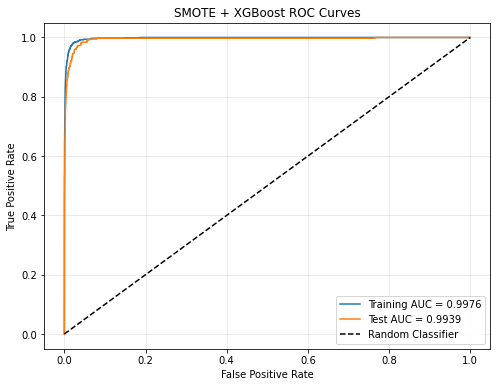

In [29]:

# Question 1(f): SMOTE + XGBoost ROC Curves and AUC

# Get predicted probabilities
smote_train_prob = smote_final.predict_proba(X_train)[:, 1]
smote_test_prob = smote_final.predict_proba(X_test)[:, 1]

# Calculate AUC
smote_train_auc = roc_auc_score(y_train, smote_train_prob)
smote_test_auc = roc_auc_score(y_test, smote_test_prob)

print("Training AUC:", round(smote_train_auc, 6))
print("Test AUC:", round(smote_test_auc, 6))

# Calculate ROC curves
fpr_train_smote, tpr_train_smote, _ = roc_curve(
    y_train, smote_train_prob
)

fpr_test_smote, tpr_test_smote, _ = roc_curve(
    y_test, smote_test_prob
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train_smote, tpr_train_smote,
    label=f"Training AUC = {smote_train_auc:.4f}"
)

plt.plot(
    fpr_test_smote, tpr_test_smote,
    label=f"Test AUC = {smote_test_auc:.4f}"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SMOTE + XGBoost ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


I used SMOTE to handle the class imbalance. SMOTE was applied only to the training data within each cross-validation fold to avoid data leakage.

I used 5-fold cross-validation to select the L1 regularization parameter. The best alpha was 1, with a CV AUC of 0.985520 and a CV error of 0.013667.

The training misclassification error was 0.010450. The test error was 0.013000. The training AUC was 0.997592. The test AUC was 0.993891.

Compared with XGBoost without SMOTE, the test error increased from 0.006500 to 0.013000, and the test AUC decreased slightly.

SMOTE improved the positive recall from 76.80% to 89.07%. The number of false negatives decreased from 87 to 41, while false positives increased from 17 to 167.

Overall, SMOTE helped the model identify more positive cases, but it also caused more false alarms. Whether this is better depends on the cost of missing a real failure compared with a false alarm.

## 2. ISLR 6.6.3



**(a) Answer: iv. Steadily decrease.**

As s increases, the constraint on the coefficients becomes weaker. The model becomes more flexible and can fit the training data better. Therefore, training RSS will decrease or stay the same.

**(b) Answer: ii. Decrease initially, then increase.**

At first, increasing s can improve the model's prediction accuracy. However, if the model becomes too flexible, it may overfit the training data. Therefore, test RSS typically decreases first and then increases.

**(c) Answer: iii. Steadily increase.**

As s increases, the model becomes more flexible and more sensitive to changes in the training data. Therefore, variance generally increases.

**(d) Answer: iv. Steadily decrease.**

A larger s allows the model to fit more complex relationships. This usually reduces the squared bias.

**(e) Answer: v. Remain constant.**

Irreducible error comes from random noise in the data. It does not depend on the model's flexibility or the value of s, so it remains constant.

## 3. ISLR 6.6.5



We have n = 2 and p = 2. The two predictors are identical, and the intercept is zero.

Let x11 = x12 = a, x21 = x22 = -a, y1 = b, and y2 = -b.

**(a) Ridge Regression**

The ridge regression optimization problem is:

$$
\min_{\beta_1,\beta_2}
(y_1-x_{11}\beta_1-x_{12}\beta_2)^2
+(y_2-x_{21}\beta_1-x_{22}\beta_2)^2
+\lambda(\beta_1^2+\beta_2^2)
$$

After substituting the given conditions, we get:

$$
\min_{\beta_1,\beta_2}
2[b-a(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2)
$$

**(b) Ridge Coefficients**

Taking partial derivatives and setting them equal to zero:

$$
-4a[b-a(\beta_1+\beta_2)]+2\lambda\beta_1=0
$$

$$
-4a[b-a(\beta_1+\beta_2)]+2\lambda\beta_2=0
$$

Subtracting the two equations:

$$
2\lambda(\beta_1-\beta_2)=0
$$

For $\lambda>0$, we get:

$$
\hat{\beta}_1=\hat{\beta}_2
$$

Therefore, ridge regression gives equal coefficients to these identical predictors.

**(c) LASSO Regression**

The LASSO optimization problem is:

$$
\min_{\beta_1,\beta_2}
2[b-a(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|)
$$

The difference from ridge regression is that LASSO uses an L1 penalty instead of an L2 penalty.

**(d) LASSO Coefficients**

The two predictors are identical, so the predictions depend only on the sum $\beta_1+\beta_2$.

Suppose the optimal sum is $t>0$. Then $(t,0)$, $(t/2,t/2)$, and $(0,t)$ all give the same predictions.

They also have the same L1 penalty:

$$
|\beta_1|+|\beta_2|=t
$$

More generally, any pair

$$
\beta_1=ut,\qquad \beta_2=(1-u)t,
\quad 0\leq u\leq1
$$

gives the same objective value.

Therefore, when the optimal sum is nonzero, LASSO can have many solutions with different coefficients. In contrast, ridge regression assigns equal coefficients to the two predictors.


## 4. ISLR 8.4.5



**1. Majority Vote**

For majority voting, each tree predicts Red if the probability is greater than 0.5. Otherwise, it predicts Green.

Among the 10 trees, 6 predict Red and 4 predict Green.

Therefore, the final classification using majority voting is **Red**.

**2. Average Probability**

For this method, we calculate the average probability of the Red class:

\[
P(Red) = \frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
= 0.45
\]

Since the average probability of Red is 0.45, the average probability of Green is 0.55.

Therefore, the final classification using average probability is **Green**.

**Conclusion**

The two methods give different results because majority voting counts the number of votes, while average probability considers the probability values from all trees.

## 5. ISLR 9.7.3

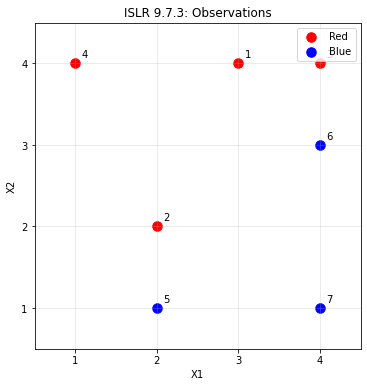

In [31]:

# Question 5(a): Plot the observations

svm_data = pd.DataFrame({
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "Class": ["Red", "Red", "Red", "Red",
              "Blue", "Blue", "Blue"]
})

plt.figure(figsize=(7, 6))

# Plot the two classes
for label, color in [("Red", "red"), ("Blue", "blue")]:
    points = svm_data[svm_data["Class"] == label]
    plt.scatter(
        points["X1"], points["X2"],
        color=color, s=90, label=label
    )

# Label each observation
for i, row in svm_data.iterrows():
    plt.annotate(
        str(i + 1),
        (row["X1"], row["X2"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("ISLR 9.7.3: Observations")
plt.xlim(0.5, 4.5)
plt.ylim(0.5, 4.5)
plt.xticks([1, 2, 3, 4])
plt.yticks([1, 2, 3, 4])
plt.gca().set_aspect("equal")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


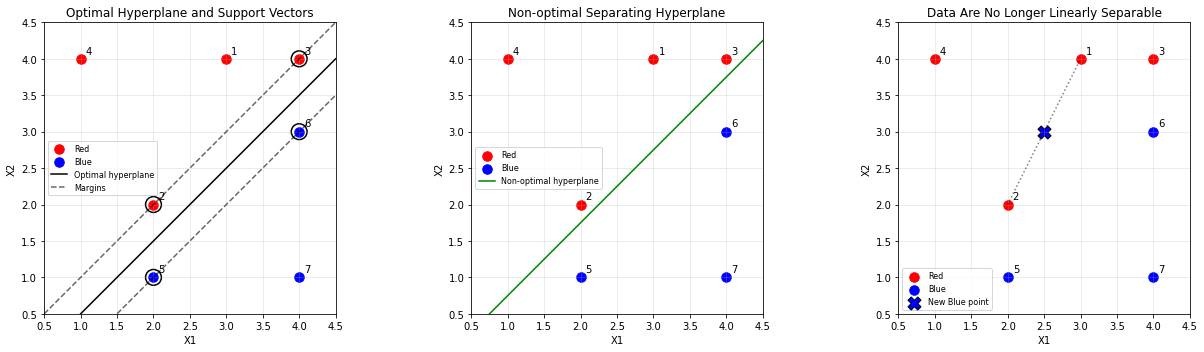

In [32]:

# Question 5(b), (d), (e), (g), (h): SVM plots

x = np.linspace(0.5, 4.5, 200)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot the original observations
for ax in axes:
    for label, color in [("Red", "red"), ("Blue", "blue")]:
        points = svm_data[svm_data["Class"] == label]
        ax.scatter(
            points["X1"], points["X2"],
            color=color, s=90, label=label
        )

    for i, row in svm_data.iterrows():
        ax.annotate(
            str(i + 1),
            (row["X1"], row["X2"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    ax.set_xlim(0.5, 4.5)
    ax.set_ylim(0.5, 4.5)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

# (b), (d), (e): Optimal hyperplane, margins, support vectors
axes[0].plot(x, x - 0.5, "k-", label="Optimal hyperplane")
axes[0].plot(x, x, "k--", alpha=0.6, label="Margins")
axes[0].plot(x, x - 1, "k--", alpha=0.6)

# Circle the support vectors: observations 2, 3, 5, 6
for obs in [2, 3, 5, 6]:
    row = svm_data.iloc[obs - 1]
    axes[0].scatter(
        row["X1"], row["X2"],
        s=250, facecolors="none",
        edgecolors="black", linewidths=1.5
    )

axes[0].set_title("Optimal Hyperplane and Support Vectors")
axes[0].legend(fontsize=8)

# (g): A non-optimal separating hyperplane
axes[1].plot(
    x, x - 0.25, "g-",
    label="Non-optimal hyperplane"
)
axes[1].set_title("Non-optimal Separating Hyperplane")
axes[1].legend(fontsize=8)

# (h): Add a new Blue observation
axes[2].scatter(
    2.5, 3,
    color="blue", marker="X", s=170,
    edgecolors="black", label="New Blue point"
)

axes[2].plot(
    [2, 3], [2, 4],
    "k:", alpha=0.5
)

axes[2].set_title("Data Are No Longer Linearly Separable")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


### Question 5: ISLR 9.7.3

**(a) Plot the observations**

I plotted the seven observations using red and blue colors to show the two classes.

**(b) Optimal separating hyperplane**

From the scatter plot, the optimal separating hyperplane is:

$$
X_2 = X_1 - 0.5
$$

Equivalently:

$$
0.5 - X_1 + X_2 = 0
$$

This line is halfway between the closest observations from the two classes.

**(c) Classification rule**

The maximal margin classifier is:

$$
f(X) = 0.5 - X_1 + X_2
$$

Therefore:

$$
\beta_0 = 0.5,\quad \beta_1 = -1,\quad \beta_2 = 1
$$

Classify an observation as Red if:

$$
0.5 - X_1 + X_2 > 0
$$

Otherwise, classify it as Blue.

**(d) Margin**

The two margin boundaries are:

$$
X_2 = X_1
$$

and

$$
X_2 = X_1 - 1
$$

The distance from the optimal hyperplane to either margin boundary is:

$$
M = \frac{0.5}{\sqrt{(-1)^2+1^2}}
= \frac{0.5}{\sqrt{2}}
\approx 0.3536
$$

Therefore, the margin is approximately 0.3536 on each side of the separating hyperplane.

**(e) Support vectors**

The support vectors are observations 2, 3, 5, and 6.

Their coordinates are:

- Observation 2: (2, 2), Red
- Observation 3: (4, 4), Red
- Observation 5: (2, 1), Blue
- Observation 6: (4, 3), Blue

These observations lie on the margin boundaries and determine the optimal separating hyperplane.

**(f) Moving observation 7**

Observation 7 is (4, 1), which is not a support vector.

It is far from the margin boundaries. A small movement of this observation would not change the closest points between the two classes.

Therefore, a slight movement of observation 7 would not affect the maximal margin hyperplane.

**(g) Non-optimal separating hyperplane**

An example of a non-optimal separating hyperplane is:

$$
X_2 = X_1 - 0.25
$$

Equivalently:

$$
0.25 - X_1 + X_2 = 0
$$

This line still separates the Red and Blue observations, but it is closer to the Red support vectors.

Therefore, its minimum margin is smaller than the optimal margin.

**(h) Add a new observation**

I added a new Blue observation at:

$$
(X_1, X_2) = (2.5, 3)
$$

This point is the midpoint of two Red observations, (2, 2) and (3, 4).

Because the new Blue observation lies between two Red observations, no linear hyperplane can separate all the Red and Blue observations correctly.

Therefore, the two classes are no longer linearly separable.